In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

from imblearn.over_sampling import SMOTE 
from sklearn.preprocessing import LabelEncoder 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, cohen_kappa_score, roc_auc_score
from sklearn.metrics import precision_score, recall_score,f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [2]:
df = pd.read_csv('Loan.csv')

In [3]:
df.head()

,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Loan
0,1152345,350,Spain,Male,54.0,1,152677.48,1,1,1,191973.49,1
1,1152346,350,Germany,Male,39.0,0,109733.20,2,0,0,123602.11,1
2,1152347,350,France,Male,51.0,10,0.00,1,1,1,125823.79,1
3,1152348,350,France,Female,35.0,3,0.00,1,0,0,113796.15,1
4,1152349,350,France,Female,59.0,0,111098.85,1,1,1,172321.21,1


In [4]:
df.shape
print(f'Number of rows {df.shape[0]}, Number of columns {df.shape[1]}')

num_var = df.select_dtypes(include=np.number).columns.tolist()
cat_Cols = df.select_dtypes(include = 'object').columns.tolist()

print('Numerical columns', num_var)
print('Categorical columns', cat_Cols)


display(df.describe())

Number of rows 1630, Number of columns 12
Numerical columns ['CustomerId', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Loan']
Categorical columns ['Geography', 'Gender']


,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Loan
count,1.630000e+03,1630.000000,1479.000000,1630.000000,1630.000000,1630.000000,1630.000000,1630.000000,1630.000000,1630.000000
mean,1.153352e+06,508.435583,38.016227,5.049693,76512.060387,1.508589,0.701227,0.489571,101016.860571,0.211043
std,1.057108e+03,50.711238,8.152538,2.858111,62438.946664,0.564653,0.457861,0.500045,57100.527663,0.408174
min,1.152345e+06,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,287.990000,0.000000
25%,1.152752e+06,480.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,53813.492500,0.000000
50%,1.153160e+06,512.000000,38.000000,5.000000,96566.615000,1.000000,1.000000,0.000000,101697.220000,0.000000
75%,1.153567e+06,533.000000,44.000000,8.000000,127544.947500,2.000000,1.000000,1.000000,149644.060000,0.000000
max,1.158803e+06,688.000000,60.000000,10.000000,221532.800000,4.000000,1.000000,1.000000,199862.750000,1.000000


In [5]:
cat_var = df.select_dtypes(include='object').columns.tolist()

for i in cat_var:
    counts = df[i].value_counts()
    pct = df[i].value_counts(normalize=True)*100
    summary = pd.DataFrame({'count':counts,'Percentage':pct.round(2)})
    print(summary)

           count  Percentage
Geography                   
France       852       52.27
Germany      404       24.79
Spain        374       22.94
        count  Percentage
Gender                   
Male      837       53.28
Female    734       46.72


In [6]:
null_count = df.isnull().sum()
null_percent = (df.isnull().sum() / len(df))*100
null_summary = pd.DataFrame({'Count':null_count, 'Percetage':null_percent})
print(null_summary)

                 Count  Percetage
CustomerId           0   0.000000
CreditScore          0   0.000000
Geography            0   0.000000
Gender              59   3.619632
Age                151   9.263804
Tenure               0   0.000000
Balance              0   0.000000
NumOfProducts        0   0.000000
HasCrCard            0   0.000000
IsActiveMember       0   0.000000
EstimatedSalary      0   0.000000
Loan                 0   0.000000


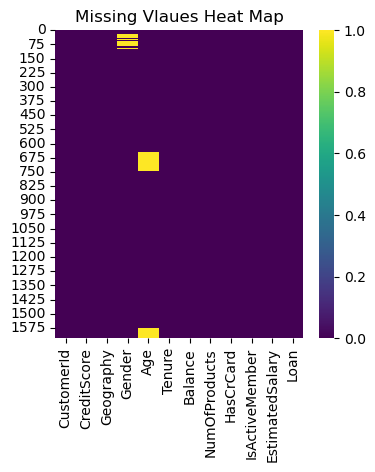

In [7]:
plt.figure(figsize=(4,4))
sns.heatmap(df.isnull(), cbar = True, cmap='viridis')
plt.title('Missing Vlaues Heat Map')
plt.show()

In [8]:
df['Age'].fillna(df['Age'].median(), inplace= True)
df['Gender'].fillna(df['Gender'].mode()[0], inplace = True)

C:\Users\HP\AppData\Local\Temp\ipykernel_14452\1704672819.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace= True)
C:\Users\HP\AppData\Local\Temp\ipykernel_14452\1704672819.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For exampl

In [9]:
num_cols = df.select_dtypes(include = np.number)
for i in num_cols:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1 
    lower_bound = Q1 - 1.5*IQR 
    upper_bound = Q3 + 1.5*IQR

    df_outlier = df[(df[i] < lower_bound) | (df[i] > upper_bound)]
    total_rows = df.shape[0]
    percentage_of_outliers = (len(df_outlier) / total_rows)*100

print("Number of outliers :", len(df_outlier))
print('percentage of outliers :', percentage_of_outliers)

Number of outliers : 344
percentage of outliers : 21.104294478527606


In [10]:
df['Loan'].value_counts(normalize=True) * 100

Loan
0    78.895706
1    21.104294
Name: proportion, dtype: float64

      Count  Percentage
Loan                   
0      1286        78.9
1       344        21.1


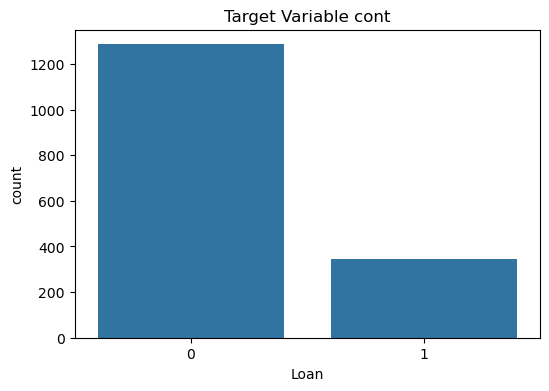

This is a class imbalance problem


In [11]:
count = df['Loan'].value_counts()
pct = df['Loan'].value_counts(normalize = True)*100
summ = pd.DataFrame({'Count':count,'Percentage':pct.round(2)})
print(summ)

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Loan')
plt.title('Target Variable cont')
plt.show()

print('This is a class imbalance problem')
# Apply SMOTE after train-test split, and only on the training data.

In [12]:
df.select_dtypes(include=['object'])

,Geography,Gender
0,Spain,Male
1,Germany,Male
2,France,Male
3,France,Female
4,France,Female
...,...,...
1625,Spain,Male
1626,France,Male
1627,Spain,Male
1628,France,Female


In [13]:
df['Geography'].value_counts()

Geography
France     852
Germany    404
Spain      374
Name: count, dtype: int64

In [14]:
df['Gender'].value_counts()

Gender
Male      896
Female    734
Name: count, dtype: int64

In [15]:
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])

In [16]:
df = pd.get_dummies(df, columns=['Geography'], drop_first=True)

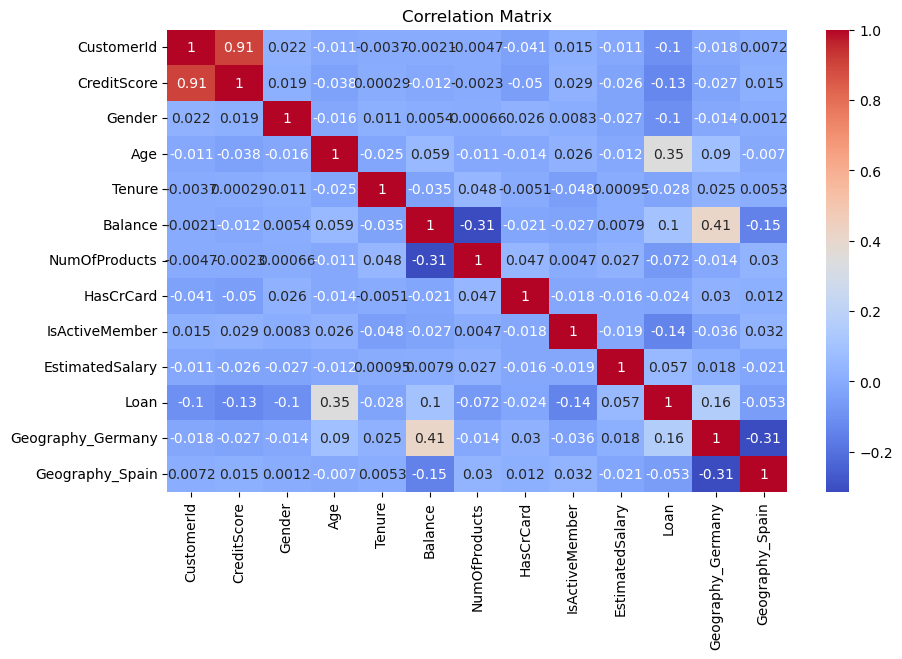

In [17]:
plt.figure(figsize = (10,6))
sns.heatmap(df.corr(), annot = True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [18]:
corr_with_target = df.corr()['Loan'].drop('Loan').sort_values(ascending=False)

print(corr_with_target)

Age                  0.346658
Geography_Germany    0.159270
Balance              0.100122
EstimatedSalary      0.057087
HasCrCard           -0.023723
Tenure              -0.027939
Geography_Spain     -0.053385
NumOfProducts       -0.071793
CustomerId          -0.102200
Gender              -0.103031
CreditScore         -0.132059
IsActiveMember      -0.142599
Name: Loan, dtype: float64


In [19]:
X = df.drop('Loan',axis = 1)
y = df['Loan']

In [20]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.30, random_state=40)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1141, 12)
X_test shape: (489, 12)
y_train shape: (1141,)
y_test shape: (489,)


In [21]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("\nROC-AUC Score:", roc_auc_score(y_test, y_test_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_test_pred))

Train Accuracy: 0.8150744960560912
Test Accuracy: 0.8057259713701431
Precision: 0.5897435897435898
Recall: 0.22549019607843138
F1 Score: 0.3262411347517731

Confusion Matrix:
 [[371  16]
 [ 79  23]]

ROC-AUC Score: 0.5920732634138927

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.96      0.89       387
           1       0.59      0.23      0.33       102

    accuracy                           0.81       489
   macro avg       0.71      0.59      0.61       489
weighted avg       0.78      0.81      0.77       489



In [22]:
smote = SMOTE(random_state = 42)
X_train_sm , y_train_sm = smote.fit_resample(X_train,y_train)
print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_sm.value_counts())

Before SMOTE: Loan
0    899
1    242
Name: count, dtype: int64
After SMOTE: Loan
0    899
1    899
Name: count, dtype: int64


In [23]:
model_smote = LogisticRegression(max_iter=1000)
model_smote.fit(X_train_sm, y_train_sm)

y_test_pred = model_smote.predict(X_test)
y_test_prob = model_smote.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_test_pred))

Accuracy: 0.7811860940695297
Precision: 0.48091603053435117
Recall: 0.6176470588235294
F1 Score: 0.5407725321888412

Confusion Matrix:
 [[319  68]
 [ 39  63]]


In [24]:
# Import models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier


# Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score

import pandas as pd
# ----------------------------
# Define Models
# ----------------------------
models = {
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}
# ----------------------------
# Store Results
# ----------------------------
results = []
# ----------------------------
# Train and Evaluate Models
# ----------------------------
for name, model in models.items():
    
    # Train model on SMOTE data
    model.fit(X_train_sm, y_train_sm)
    
    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)
    
    results.append([name, acc, prec, rec, f1, roc])

# ----------------------------
# Create Results Table
# ----------------------------
results_df = pd.DataFrame(results, 
                          columns=["Model", "Accuracy", "Precision", 
                                   "Recall", "F1 Score", "ROC-AUC"])

# Sort by Recall (since this is important for loan default)
results_df = results_df.sort_values(by="Recall", ascending=False)

print(results_df)

C:\Users\HP\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:35:08] WARNING: C:\b\abs_d97hy_84m6\croot\xgboost-split_1749630932152\work\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


               Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
1        Naive Bayes  0.609407   0.321285  0.784314  0.455840  0.750317
4  Gradient Boosting  0.811861   0.545455  0.588235  0.566038  0.829711
5            XGBoost  0.803681   0.527778  0.558824  0.542857  0.804808
3      Random Forest  0.783231   0.481481  0.509804  0.495238  0.800958
2      Decision Tree  0.756646   0.429752  0.509804  0.466368  0.665755
0                KNN  0.582822   0.225806  0.411765  0.291667  0.519367
